Dataset Shape: (499000, 14)

Training Shape: (399200, 3)
Testing Shape: (99800, 3)

K-Means Training Completed!

Training Cluster Distribution:
0     33558
1    144842
2    220800
Name: count, dtype: int64

Testing Cluster Distribution:
0     8229
1    36318
2    55253
Name: count, dtype: int64

Cluster Summary:
         AnnualIncome  AnnualPurchaseAmount  PurchaseFrequency
Cluster                                                       
0           124184.93              34714.11              19.41
1            83023.86              16004.09              10.94
2            48551.79               7534.09               5.40

Customer Segment Distribution:
CustomerSegment
Budget     220800
Regular    144842
Premium     33558
Name: count, dtype: int64

Silhouette Score: 0.3659


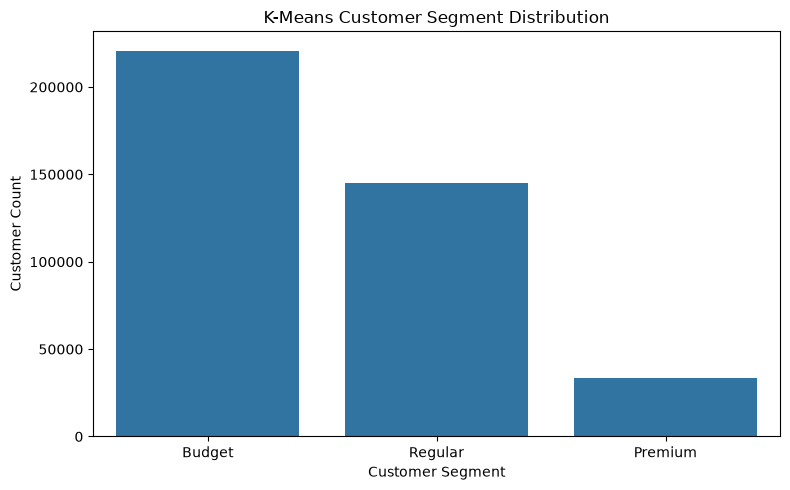


K-Means Model Saved Successfully!


In [ ]:

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Load Dataset
df = pd.read_csv("Data/Main_Clean.csv")

print("Dataset Shape:", df.shape)

# 2. Feature Selection
features = [
    "AnnualIncome",
    "AnnualPurchaseAmount",
    "PurchaseFrequency"
]

X = df[features].copy()

# 3. Train-Test Split
X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

# 4. K-Means Pipeline
kmeans_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ))
])

# 5. Train Model
kmeans_pipeline.fit(X_train)

train_clusters = kmeans_pipeline.predict(X_train)
test_clusters = kmeans_pipeline.predict(X_test)

print("\nK-Means Training Completed!")

print("\nTraining Cluster Distribution:")
print(pd.Series(train_clusters).value_counts().sort_index())

print("\nTesting Cluster Distribution:")
print(pd.Series(test_clusters).value_counts().sort_index())

# 6. Cluster Summary
train_result = X_train.copy()
train_result["Cluster"] = train_clusters

cluster_summary = train_result.groupby(
    "Cluster"
)[features].mean().round(2)

print("\nCluster Summary:")
print(cluster_summary)

# 7. Assign Customer Segment Names
ordered_clusters = (
    cluster_summary["AnnualPurchaseAmount"]
    .sort_values(ascending=False)
    .index.tolist()
)

cluster_names = {
    ordered_clusters[0]: "Premium",
    ordered_clusters[1]: "Regular",
    ordered_clusters[2]: "Budget"
}

train_result["CustomerSegment"] = (
    train_result["Cluster"].map(cluster_names)
)

print("\nCustomer Segment Distribution:")
print(train_result["CustomerSegment"].value_counts())

# 8. Silhouette Score
X_train_scaled = kmeans_pipeline.named_steps["scaler"].transform(
    kmeans_pipeline.named_steps["imputer"].transform(X_train)
)

score = silhouette_score(
    X_train_scaled,
    train_clusters,
    sample_size=10000,
    random_state=42
)

print("\nSilhouette Score:", round(score, 4))

# 9. Segment Visualization
segment_distribution = train_result["CustomerSegment"].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(
    x=segment_distribution.index,
    y=segment_distribution.values
)

plt.title("K-Means Customer Segment Distribution")
plt.xlabel("Customer Segment")
plt.ylabel("Customer Count")
plt.tight_layout()
plt.show()

# # 10. Save Trained Model
# model_data = {
#     "pipeline": kmeans_pipeline,
#     "cluster_names": cluster_names,
#     "features": features
# }

# joblib.dump(model_data, "Models/kmeans_model.pkl")

# print("\nK-Means Model Saved Successfully!")
